# MEIKURAL Version 3 — handpicked batch reports

Every recording gets one image containing filename, folder ground truth, predicted raag, seven-score timeline, and duration-weighted overall ranking. The final two cells show song-level and chunk-level confusion matrices.

**Version 3 uses native STFT magnitudes without tonic estimation or frequency-axis manipulation.** It requires a separately trained `models/ver3/latest.pt` checkpoint. The larger CNN accepts full 4,097 × 1,292 inputs with 32/64/128 filters and a 256-unit hidden classifier.

The test root defaults to the existing shared `data/test_ver1_handpicked` collection. Outputs are separate under `outputs/ver3/handpicked`. Run cells in order using Python (MEIKURAL). No training is performed by this notebook.

**Shared test audio:** all versions use `data/test_ver1_handpicked`, including its `marwa` folder. Checkpoints, feature caches, and reports remain version-specific. After adding files, rerun the recording-list and batch cells (or Run All) before reading the confusion matrices. Saved outputs are not refreshed automatically.

In [1]:
from pathlib import Path
import pickle
import sys

import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "src/ver3/config.json").is_file(), "Launch from the repository root or notebooks/"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.ver3.config import load_config, resolve_path
from src.ver3.inference.predict import load_model, predict
from src.ver3.inference.report import performance_figure, recording_labels

config = load_config()


## Paths

The defaults use the handpicked collection and trained Version 3 model. Set `DEVICE = "cuda"` to require GPU inference, `"cpu"` to force CPU, or leave `"auto"` to select the available device. Images are saved beneath `OUTPUT_DIR`, preserving the raag-folder structure.

`TEST_DIR` defaults to the existing `data/test_ver1_handpicked` collection so all three versions can be evaluated on the same recordings. Change this path only if you create a different collection. `CHECKPOINT_PATH` and `OUTPUT_DIR` remain Version 3-specific.

In [2]:
TEST_DIR = ROOT / "data/test_ver1_handpicked"  # Shared raw test audio for all three versions.
CHECKPOINT_PATH = resolve_path(config["paths"]["run"]) / "latest.pt"
OUTPUT_DIR = ROOT / "outputs/ver3/handpicked"
DEVICE = "auto"


## Inspect the recording list

Labels come from the first folder below `TEST_DIR`, including when files are nested more deeply. `sree` maps to `Shree`; underscores and hyphens act as spaces, so `miyan_malhar` maps to `Miyan Malhar`. Unknown labels remain unchanged and are marked as outside the model classes. In particular, **Bhairav is not renamed Bhairavi**.

In [3]:
# Check the checkpoint and use its saved class names, independent of config edits.
model, checkpoint_config, _ = load_model(CHECKPOINT_PATH, device="cpu")
classes = checkpoint_config["classes"]
del model

TEST_DIR = Path(TEST_DIR).expanduser().resolve()
OUTPUT_DIR = Path(OUTPUT_DIR).expanduser().resolve()
if OUTPUT_DIR == TEST_DIR or TEST_DIR in OUTPUT_DIR.parents or OUTPUT_DIR in TEST_DIR.parents:
    raise ValueError("Keep report images separate from the test collection")
recordings = recording_labels(TEST_DIR, classes)
print(f"Found {len(recordings)} recordings. Supported model classes: {', '.join(classes)}")
for audio_path, expected in recordings:
    print(f"{expected:15s} | {audio_path.relative_to(TEST_DIR)}")


Found 20 recordings. Supported model classes: Shree, Jog, Miyan Malhar, Lalit, Todi, Marwa, Bhairavi
Bhairavi        | bhairavi/Bhimsen_Joshi.mp3
Bhairavi        | bhairavi/NFAK.mp3
Jog             | jog/Venkatesh_kumar.mp3
Jog             | jog/rashid_khan.mp3
Lalit           | lalit/Bhimsen Joshi - Raag Lalit Lalat (1961).mp3
Lalit           | lalit/Pandit Venkatesh Kumar Raag Lalit Vilambit & Drut Ektaal.mp3
Marwa           | marwa/AudioTranscriberAI_Indian Classical Music Recording 5 M. Venkatesh Kumar - Raga Marwa.mp3
Marwa           | marwa/Padma Bhushan Ustaad Rashid Khan - Raag Marwa.mp3
Marwa           | marwa/Sanjeev Abhyankar Raag Marwa Part 1 - Piya Nahi Aaye.mp3
Miyan Malhar    | miyan_malhar/Bhimsen Joshi - Miyan Ki Malhar Complete.mp3
Miyan Malhar    | miyan_malhar/Pt. Venkatesh Kumar Miyan ki malhar Bazm e khas live baithak.mp3
Miyan Malhar    | miyan_malhar/Raag Miyan Malhar Vidushi Ashwini Bhide Hindustani Classical Vocal Komal Nishad Baroda Part 1 7.mp3
Miyan Malhar 

## Run all recordings

This cell performs inference. Each recording gets a single combined figure, displayed inline and saved as a PNG. Scores on the right are taken directly from `predict()`; no new averaging formula is introduced. File names retain their audio extension in the PNG name to distinguish, for example, `performance.mp3.png` from `performance.wav.png`. Rerunning replaces reports at the same output paths.

A recording that fails receives an error figure, and the batch continues. Interrupting the kernel still stops the batch normally. Per-recording summaries remain in `summaries`; only per-window predicted labels are retained for the confusion matrices, rather than all per-window scores.

[1/20] bhairavi/Bhimsen_Joshi.mp3


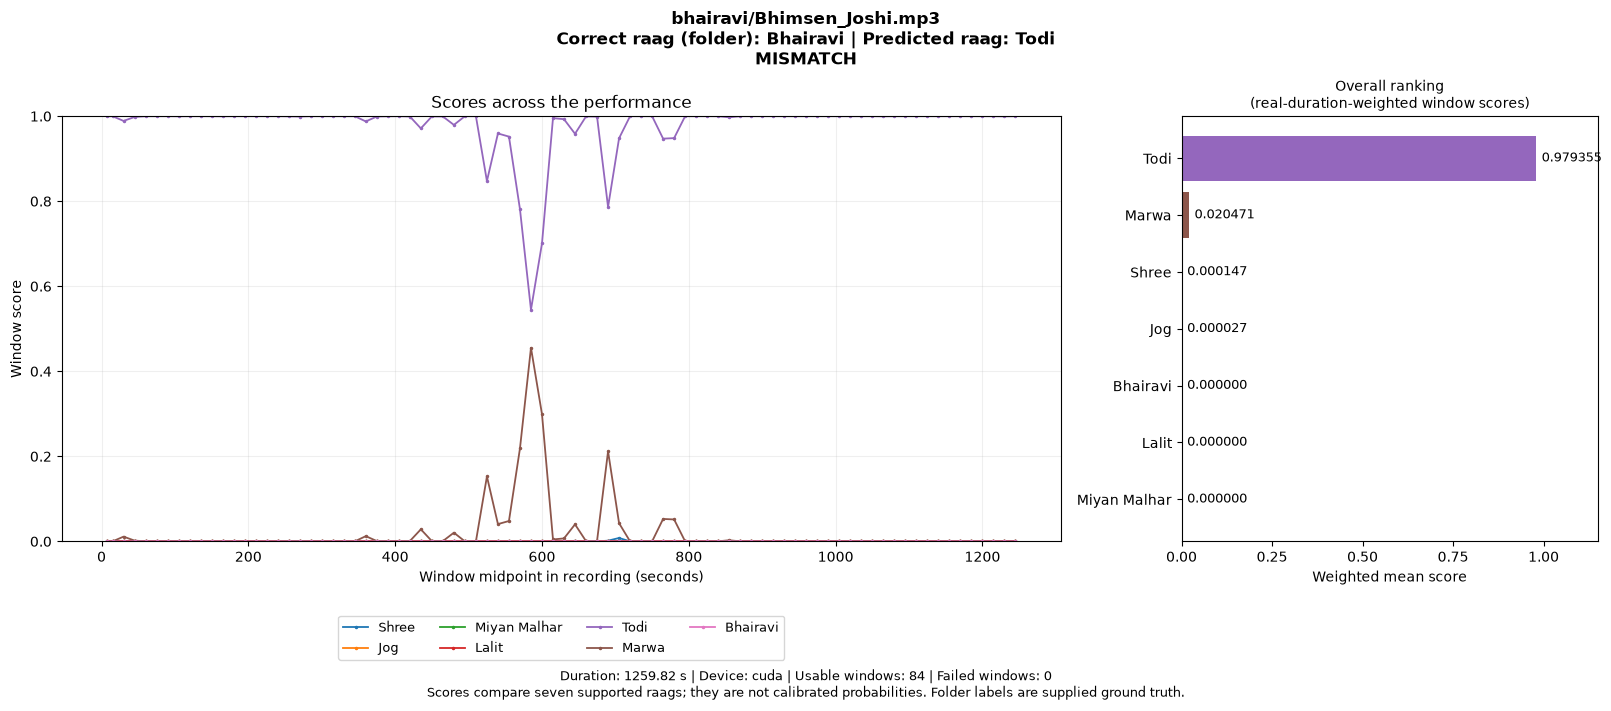

Saved: /home/mushu-cislab/GitHub/MEIKURAL/outputs/ver3/handpicked/bhairavi/Bhimsen_Joshi.mp3.png
[2/20] bhairavi/NFAK.mp3


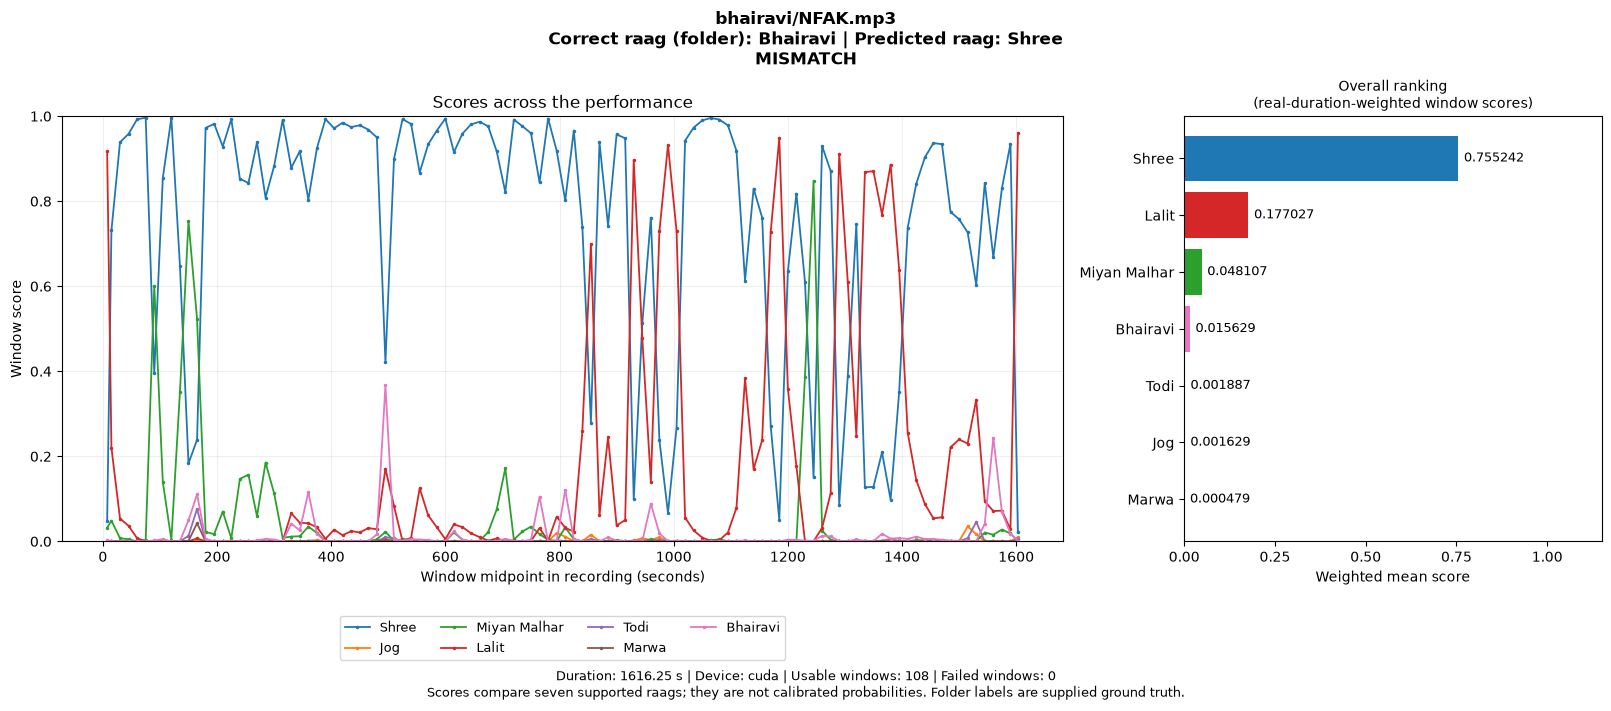

Saved: /home/mushu-cislab/GitHub/MEIKURAL/outputs/ver3/handpicked/bhairavi/NFAK.mp3.png
[3/20] jog/Venkatesh_kumar.mp3


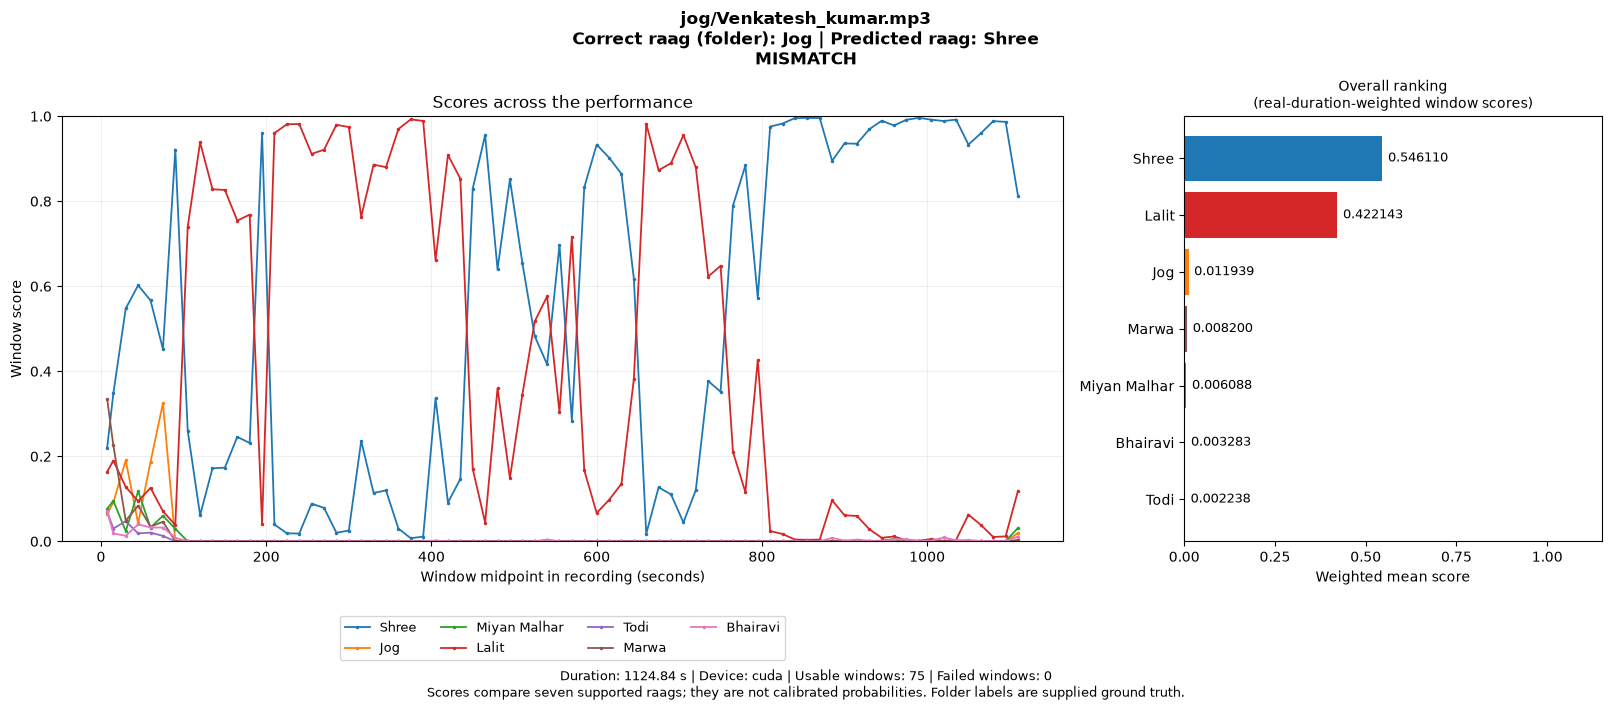

Saved: /home/mushu-cislab/GitHub/MEIKURAL/outputs/ver3/handpicked/jog/Venkatesh_kumar.mp3.png
[4/20] jog/rashid_khan.mp3


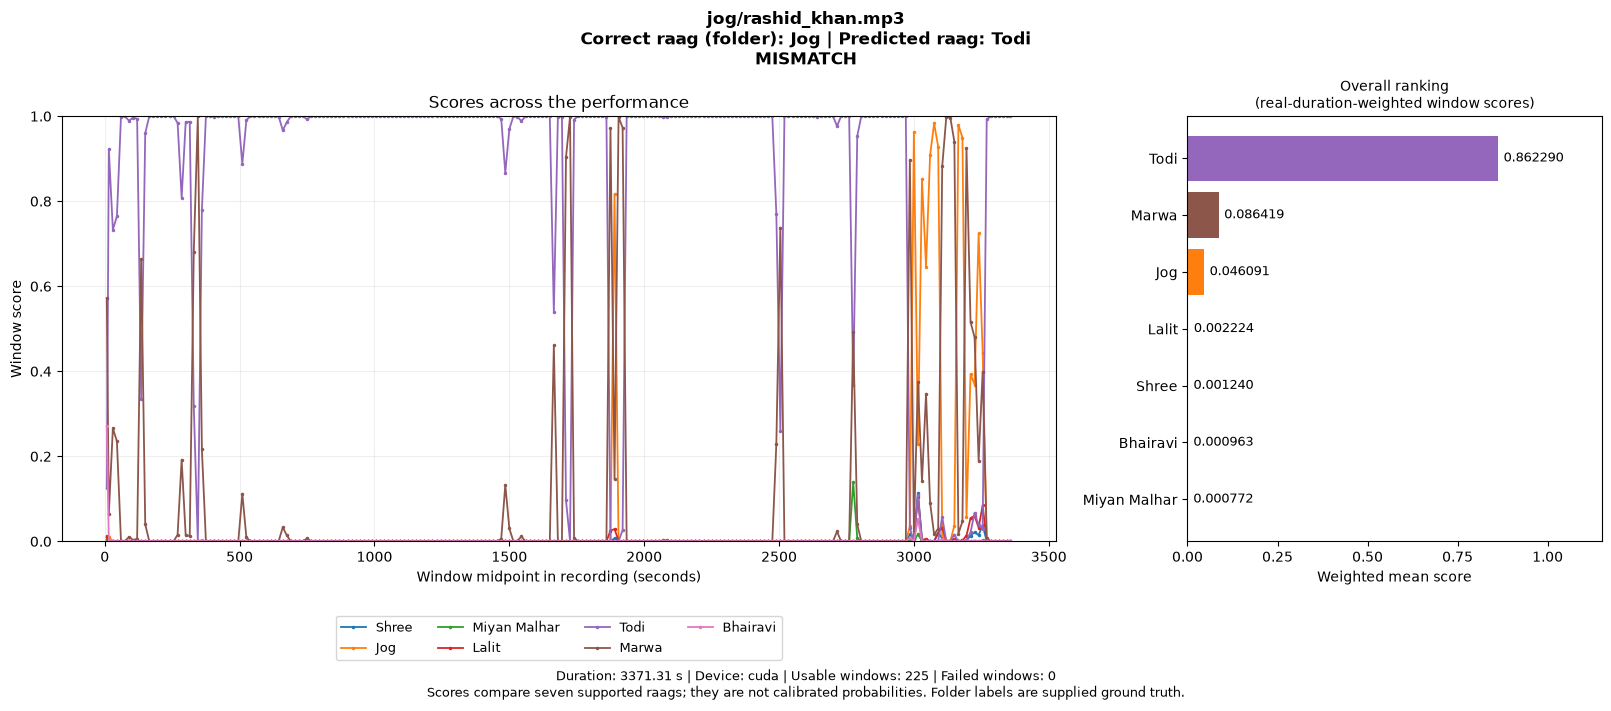

Saved: /home/mushu-cislab/GitHub/MEIKURAL/outputs/ver3/handpicked/jog/rashid_khan.mp3.png
[5/20] lalit/Bhimsen Joshi - Raag Lalit Lalat (1961).mp3


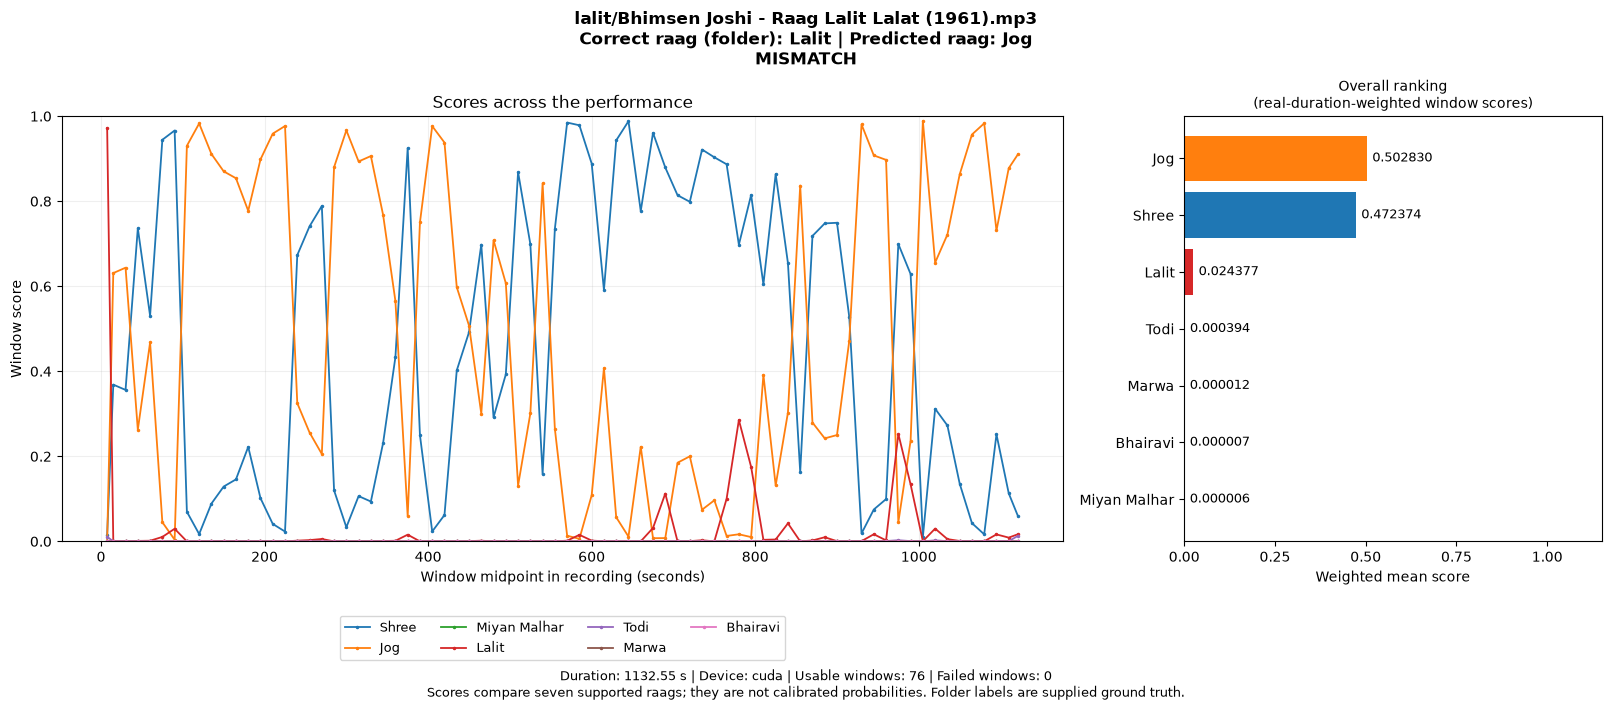

Saved: /home/mushu-cislab/GitHub/MEIKURAL/outputs/ver3/handpicked/lalit/Bhimsen Joshi - Raag Lalit Lalat (1961).mp3.png
[6/20] lalit/Pandit Venkatesh Kumar Raag Lalit Vilambit & Drut Ektaal.mp3


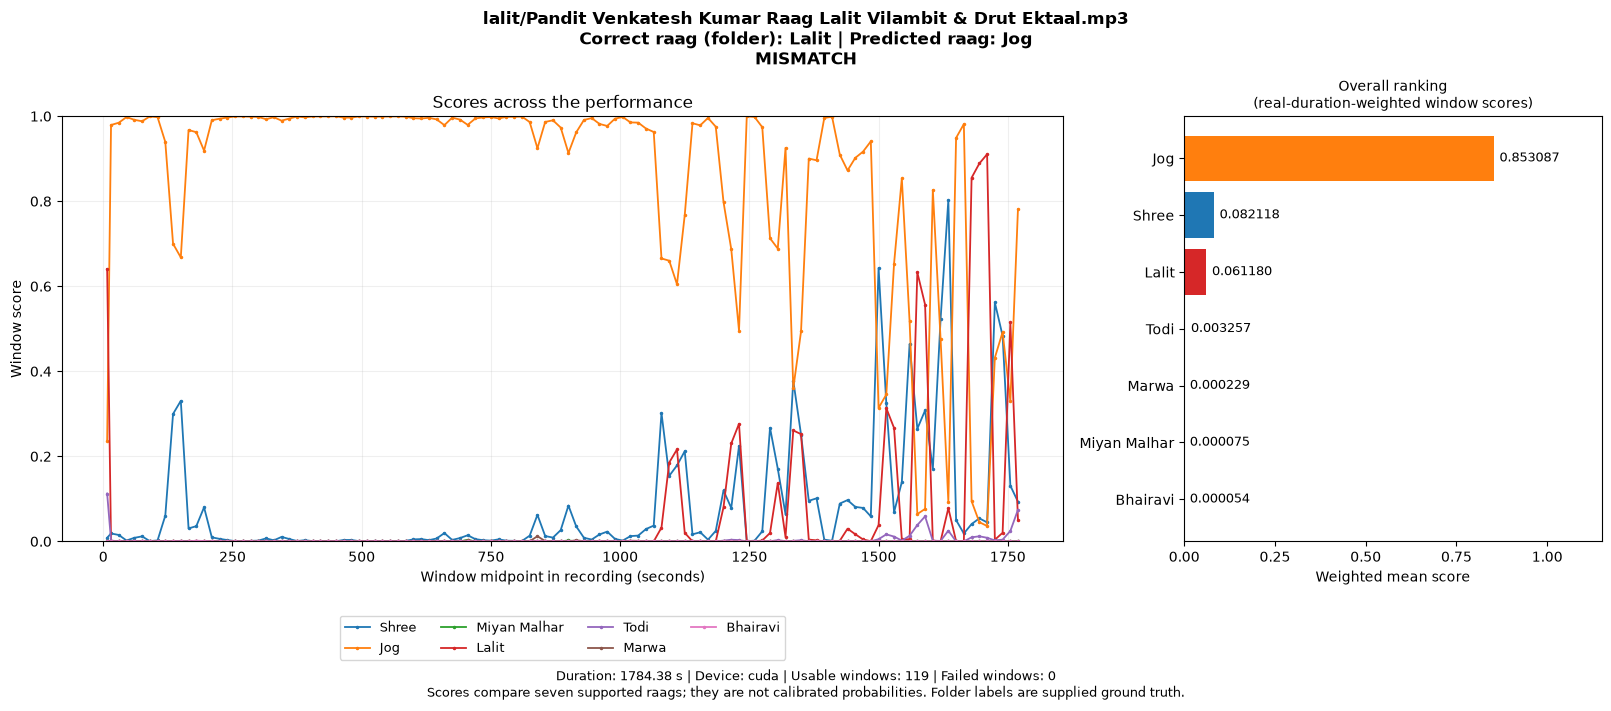

Saved: /home/mushu-cislab/GitHub/MEIKURAL/outputs/ver3/handpicked/lalit/Pandit Venkatesh Kumar Raag Lalit Vilambit & Drut Ektaal.mp3.png
[7/20] marwa/AudioTranscriberAI_Indian Classical Music Recording 5 M. Venkatesh Kumar - Raga Marwa.mp3


[src/libmpg123/parse.c:skip_junk():1260] error: Giving up searching valid MPEG header after 65536 bytes of junk.


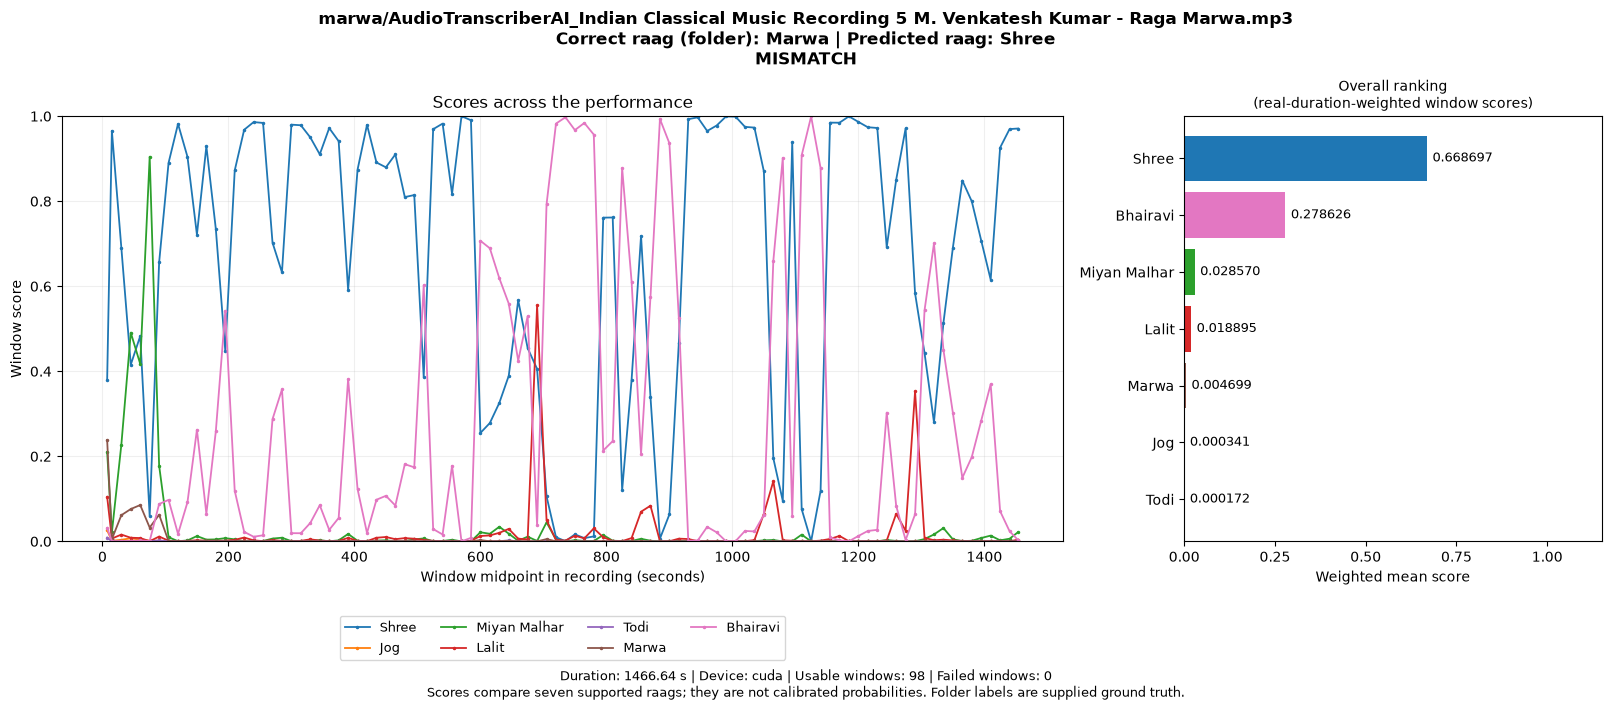

Saved: /home/mushu-cislab/GitHub/MEIKURAL/outputs/ver3/handpicked/marwa/AudioTranscriberAI_Indian Classical Music Recording 5 M. Venkatesh Kumar - Raga Marwa.mp3.png
[8/20] marwa/Padma Bhushan Ustaad Rashid Khan - Raag Marwa.mp3


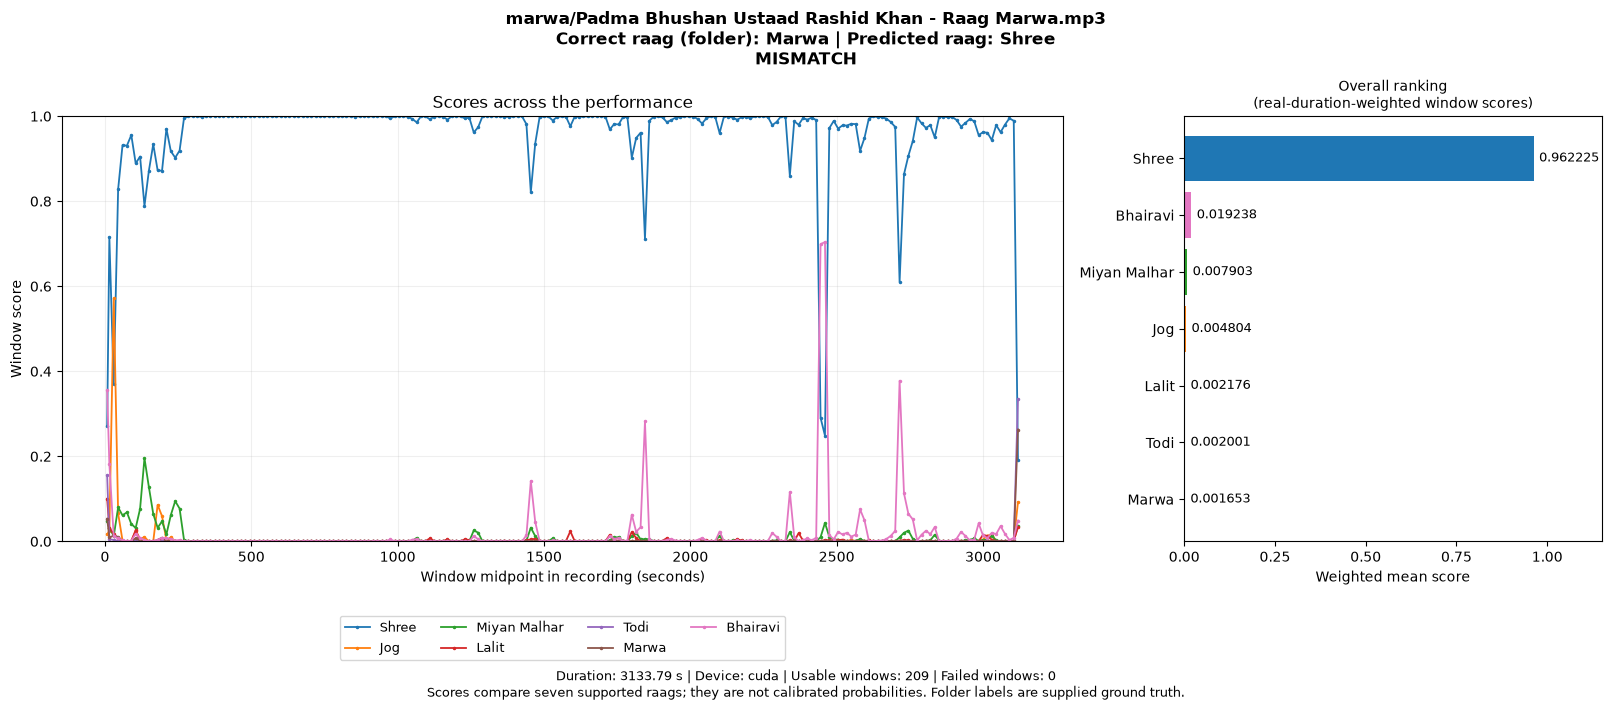

Saved: /home/mushu-cislab/GitHub/MEIKURAL/outputs/ver3/handpicked/marwa/Padma Bhushan Ustaad Rashid Khan - Raag Marwa.mp3.png
[9/20] marwa/Sanjeev Abhyankar Raag Marwa Part 1 - Piya Nahi Aaye.mp3


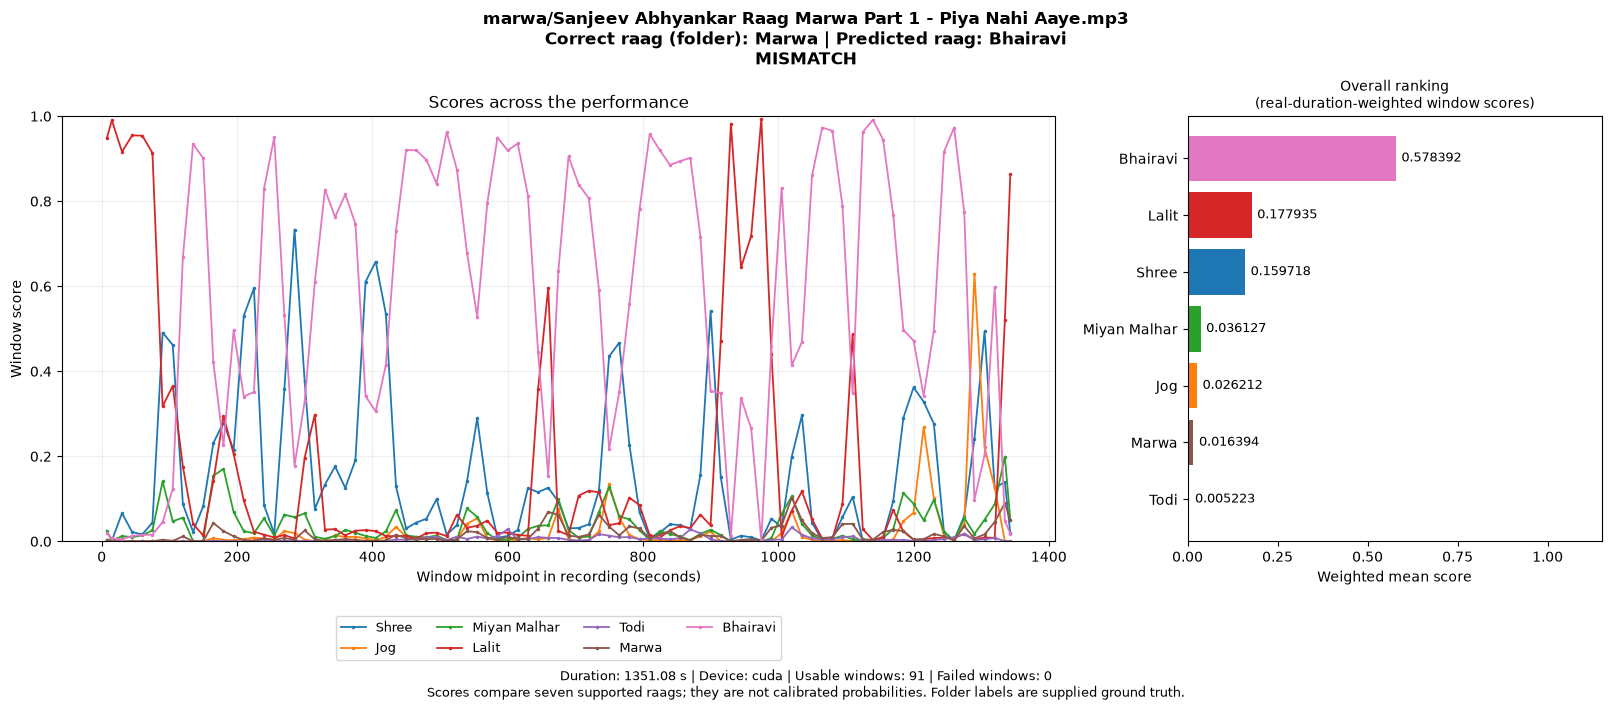

Saved: /home/mushu-cislab/GitHub/MEIKURAL/outputs/ver3/handpicked/marwa/Sanjeev Abhyankar Raag Marwa Part 1 - Piya Nahi Aaye.mp3.png
[10/20] miyan_malhar/Bhimsen Joshi - Miyan Ki Malhar Complete.mp3


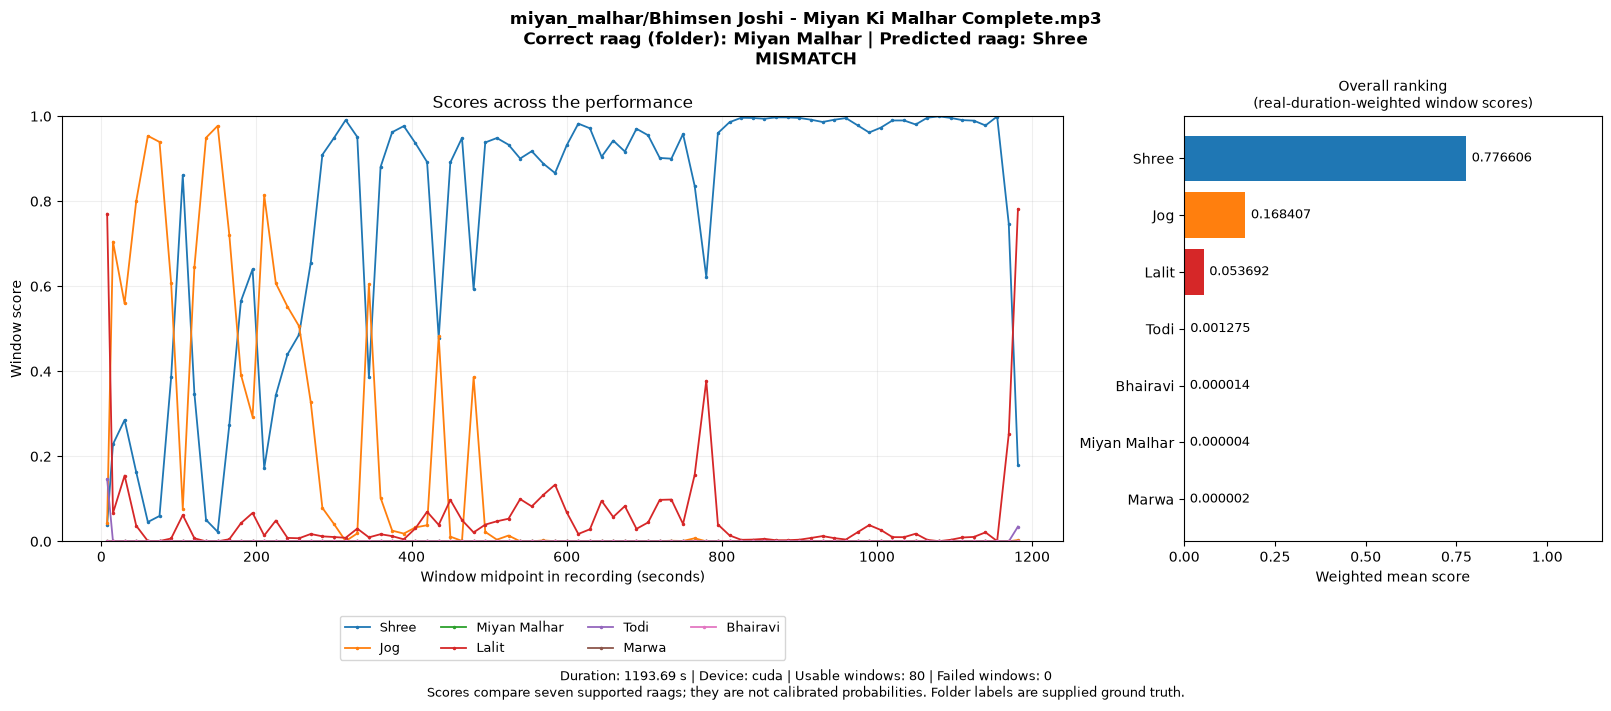

Saved: /home/mushu-cislab/GitHub/MEIKURAL/outputs/ver3/handpicked/miyan_malhar/Bhimsen Joshi - Miyan Ki Malhar Complete.mp3.png
[11/20] miyan_malhar/Pt. Venkatesh Kumar Miyan ki malhar Bazm e khas live baithak.mp3


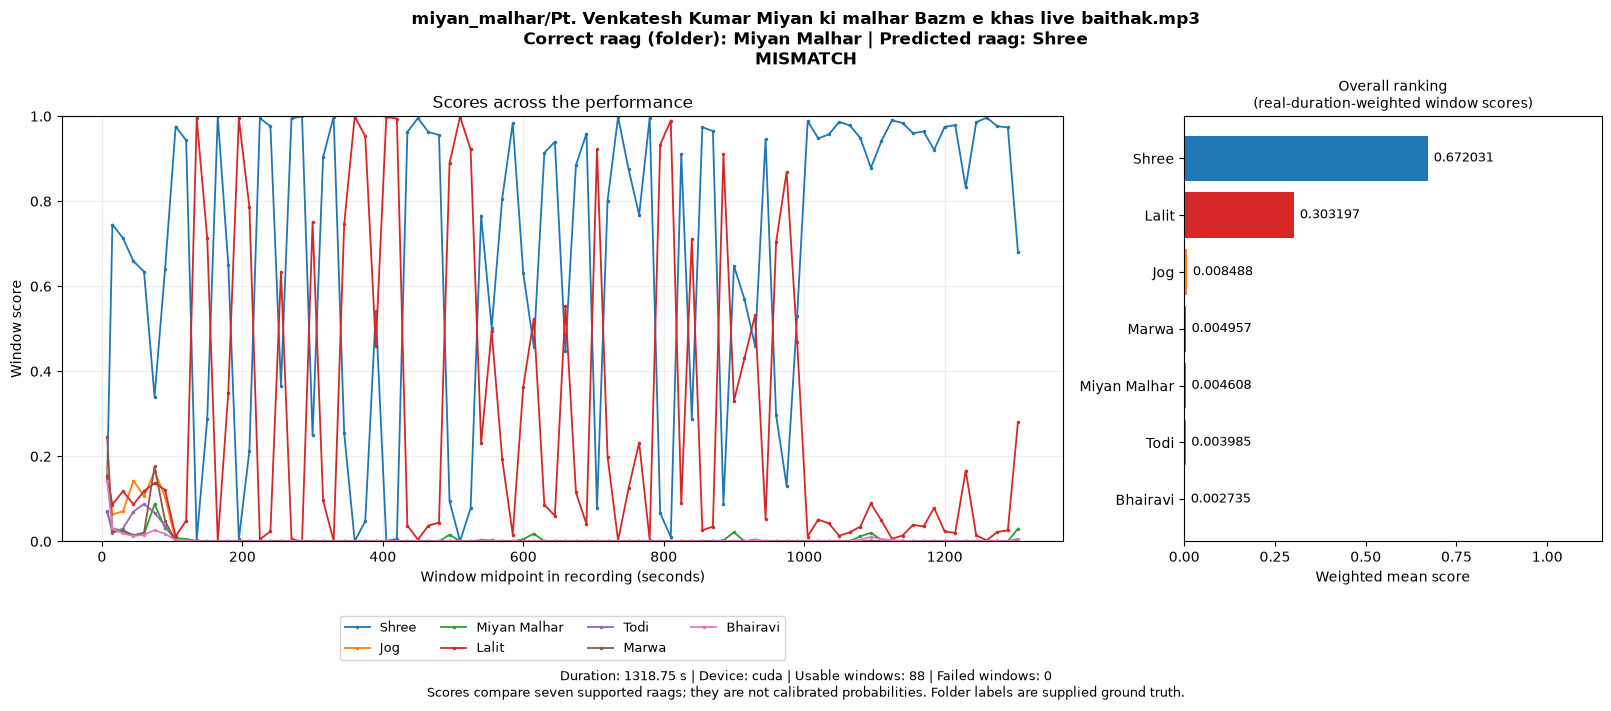

Saved: /home/mushu-cislab/GitHub/MEIKURAL/outputs/ver3/handpicked/miyan_malhar/Pt. Venkatesh Kumar Miyan ki malhar Bazm e khas live baithak.mp3.png
[12/20] miyan_malhar/Raag Miyan Malhar Vidushi Ashwini Bhide Hindustani Classical Vocal Komal Nishad Baroda Part 1 7.mp3


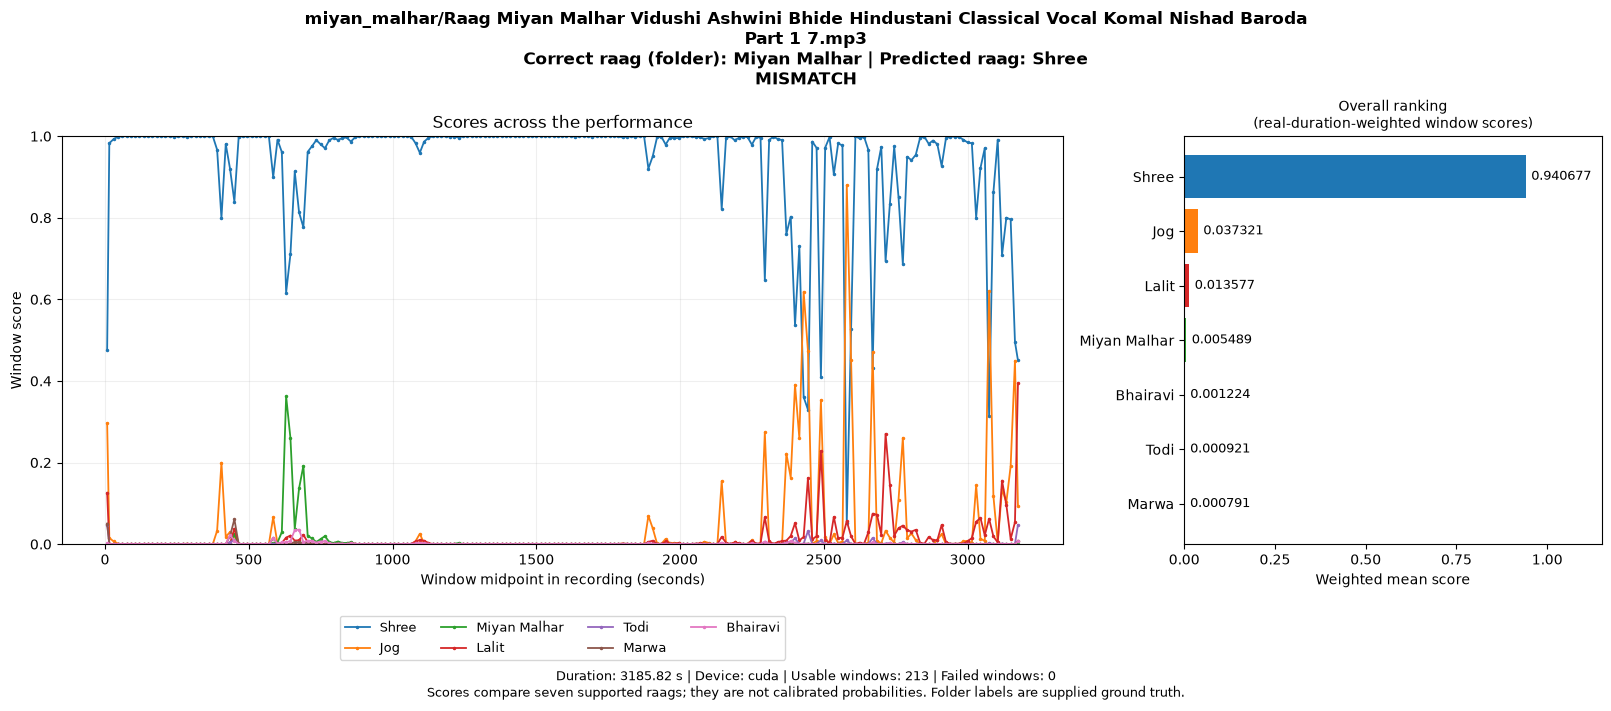

Saved: /home/mushu-cislab/GitHub/MEIKURAL/outputs/ver3/handpicked/miyan_malhar/Raag Miyan Malhar Vidushi Ashwini Bhide Hindustani Classical Vocal Komal Nishad Baroda Part 1 7.mp3.png
[13/20] miyan_malhar/Ustad Salamat Ali Khan - Raag Miyan Ki Malhar(in Satyajit Ray's film Jalsaghar or The Music Room ).mp3


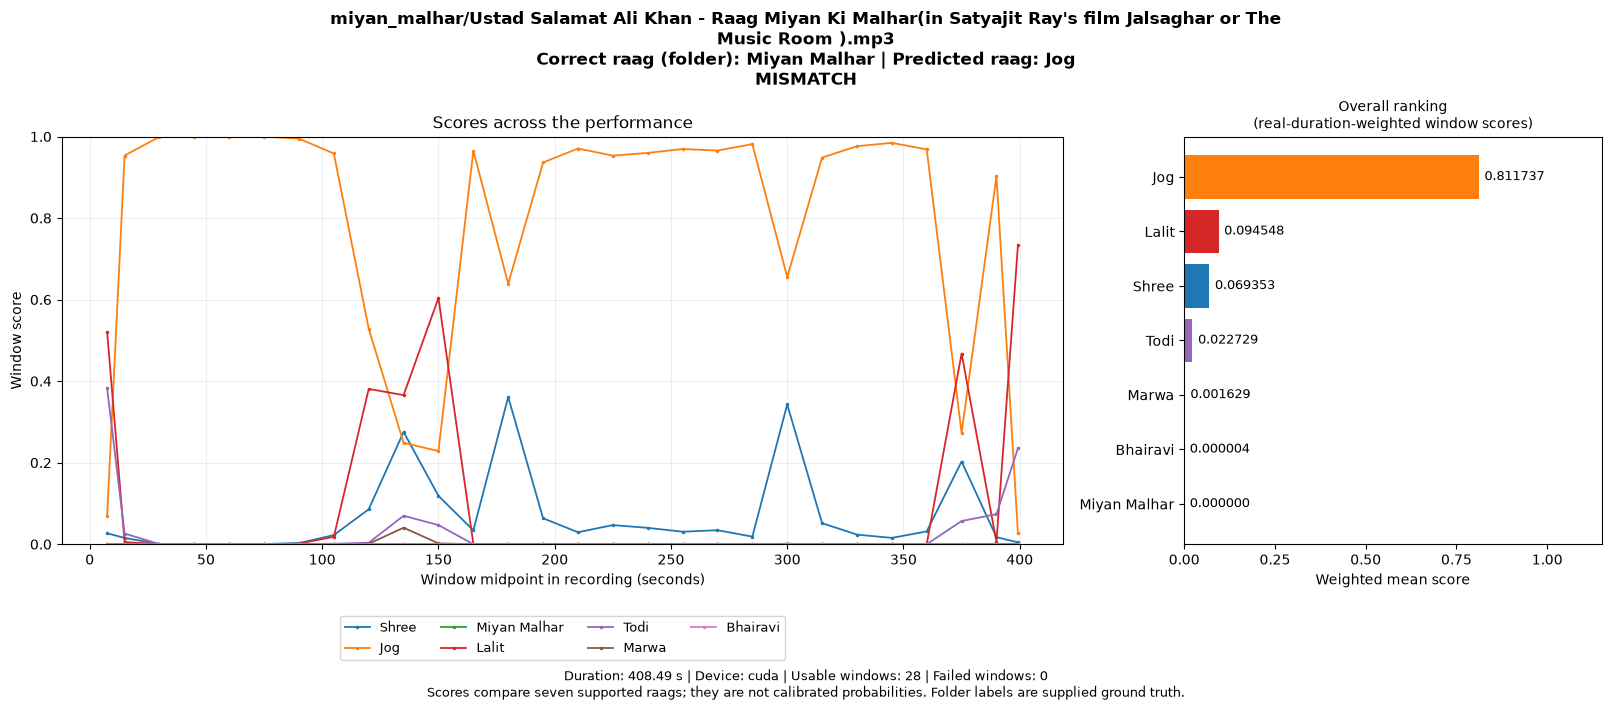

Saved: /home/mushu-cislab/GitHub/MEIKURAL/outputs/ver3/handpicked/miyan_malhar/Ustad Salamat Ali Khan - Raag Miyan Ki Malhar(in Satyajit Ray's film Jalsaghar or The Music Room ).mp3.png
[14/20] miyan_malhar/Vidushi Kishori Amonkar (vocal) - Raga Miyan ki Malhar.mp3


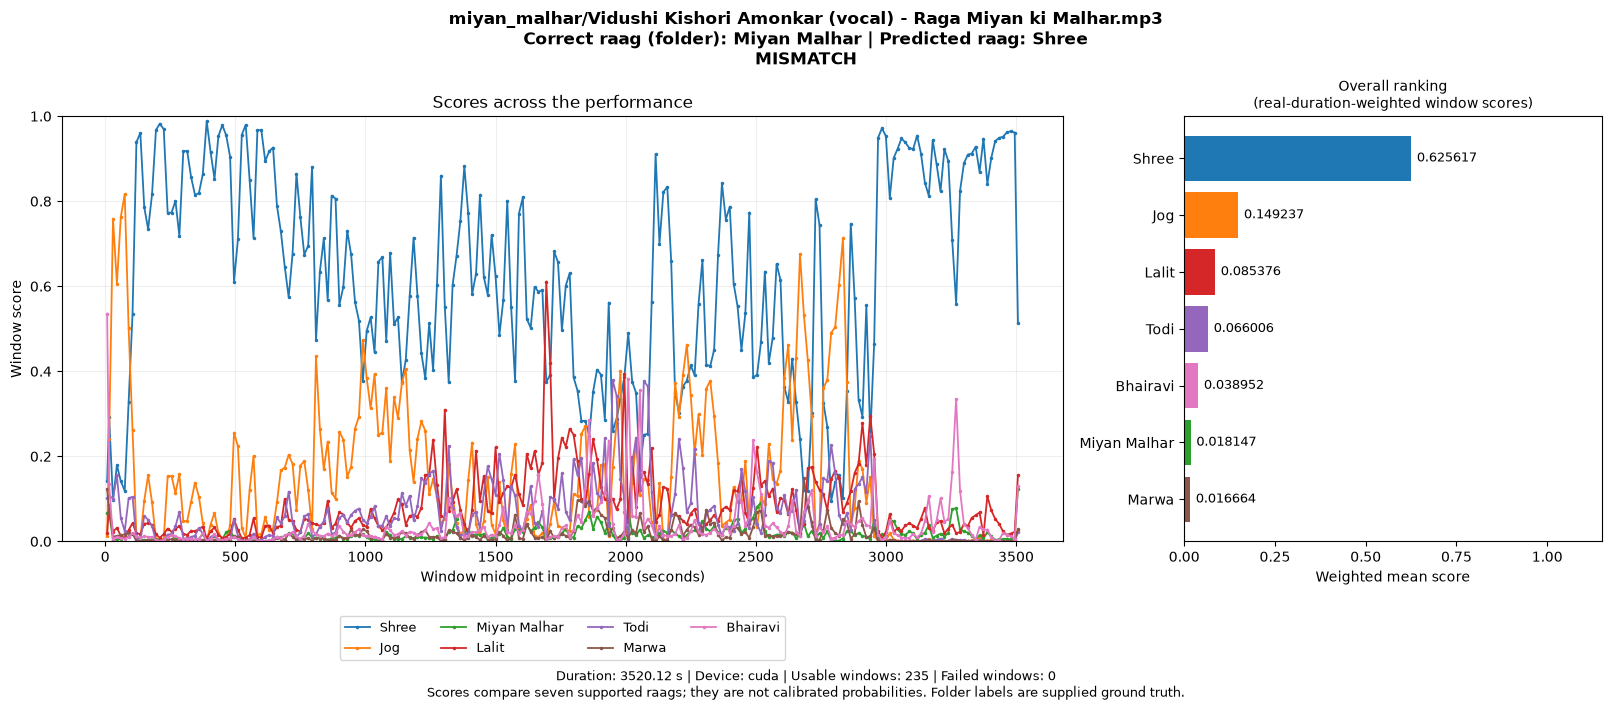

Saved: /home/mushu-cislab/GitHub/MEIKURAL/outputs/ver3/handpicked/miyan_malhar/Vidushi Kishori Amonkar (vocal) - Raga Miyan ki Malhar.mp3.png
[15/20] sree/Gundecha_Brothers_Raag_Shree.mp3


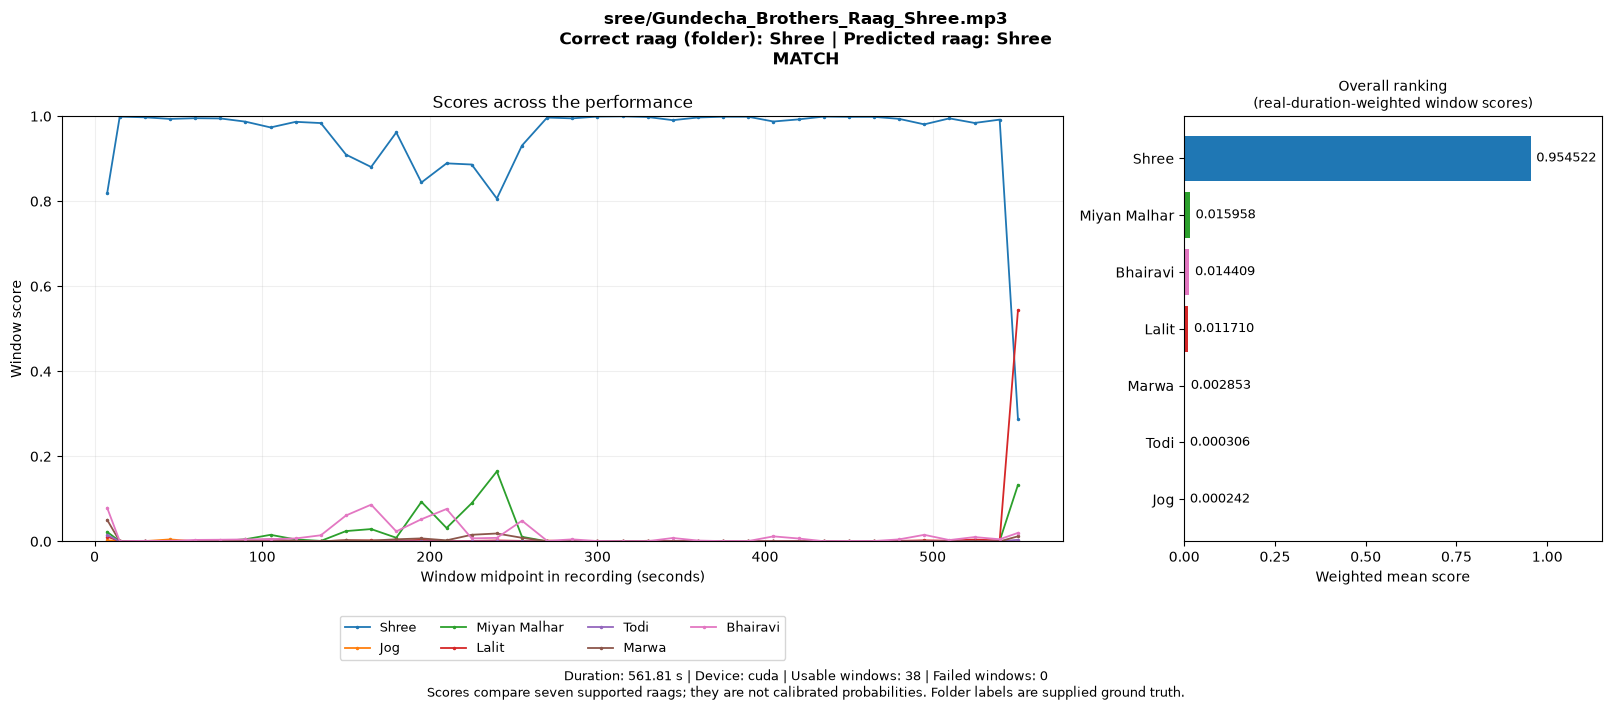

Saved: /home/mushu-cislab/GitHub/MEIKURAL/outputs/ver3/handpicked/sree/Gundecha_Brothers_Raag_Shree.mp3.png
[16/20] sree/Ustad_Rashid_Khan.mp3


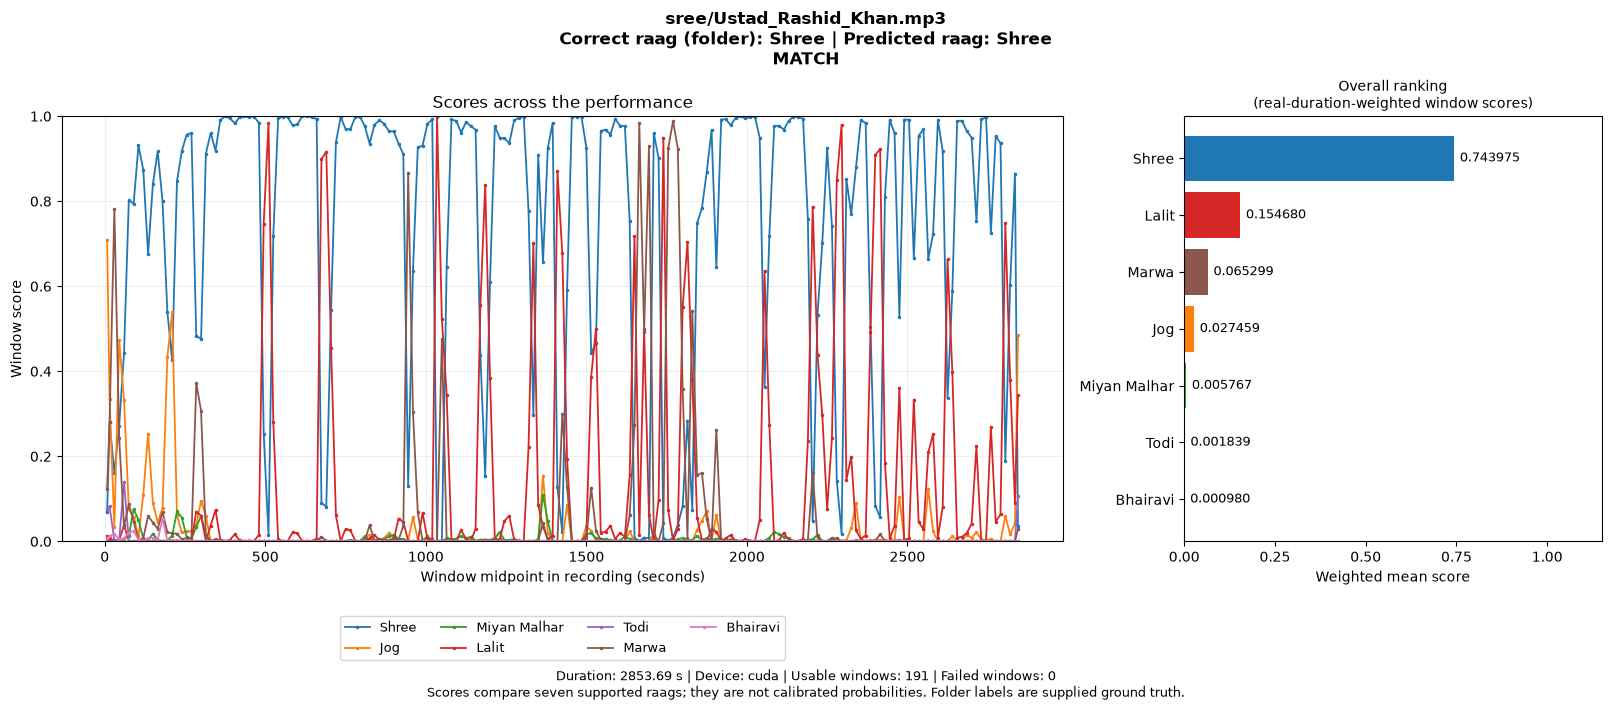

Saved: /home/mushu-cislab/GitHub/MEIKURAL/outputs/ver3/handpicked/sree/Ustad_Rashid_Khan.mp3.png
[17/20] sree/Venkatesh_Kumar.mp3


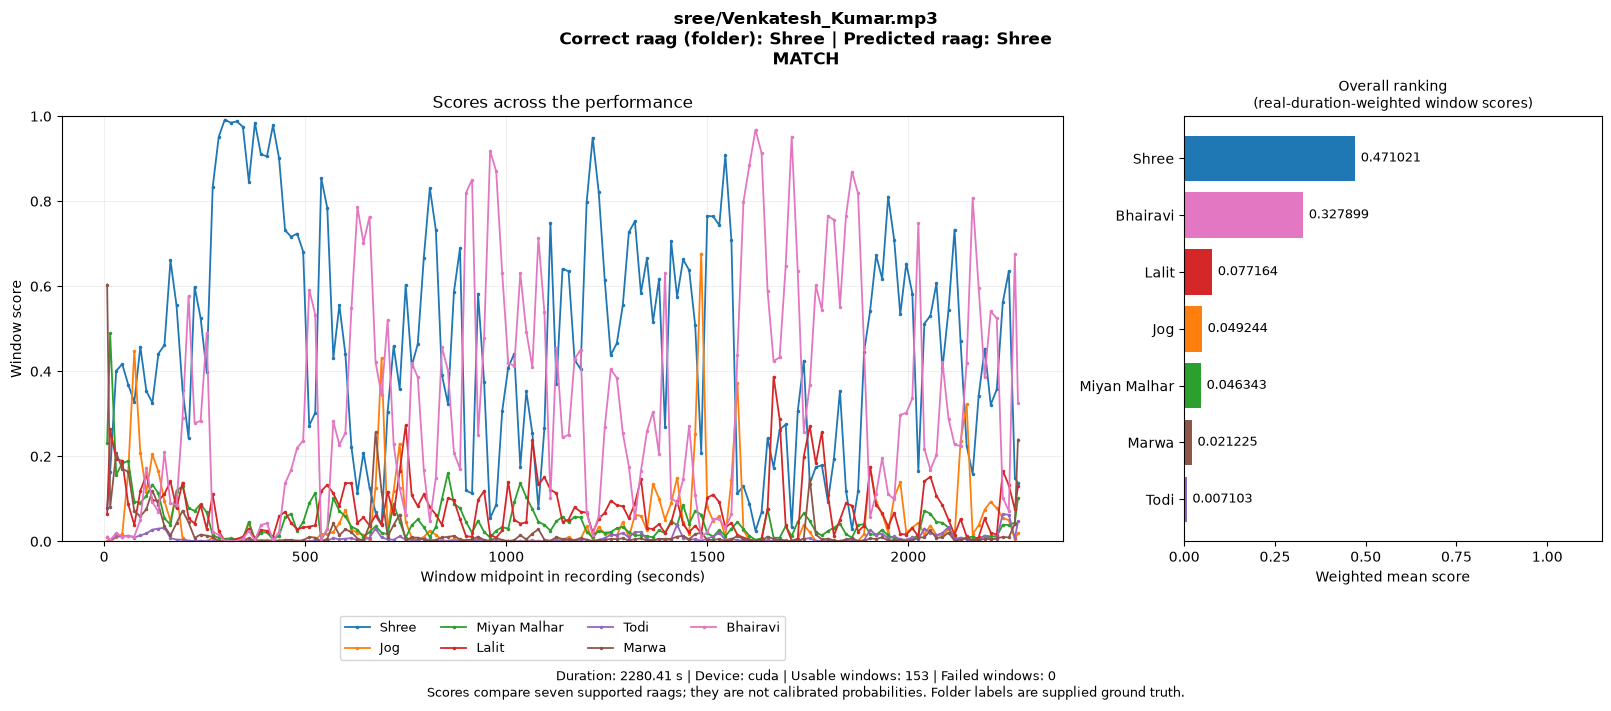

Saved: /home/mushu-cislab/GitHub/MEIKURAL/outputs/ver3/handpicked/sree/Venkatesh_Kumar.mp3.png
[18/20] todi/Kishori_Amonkar.mp3


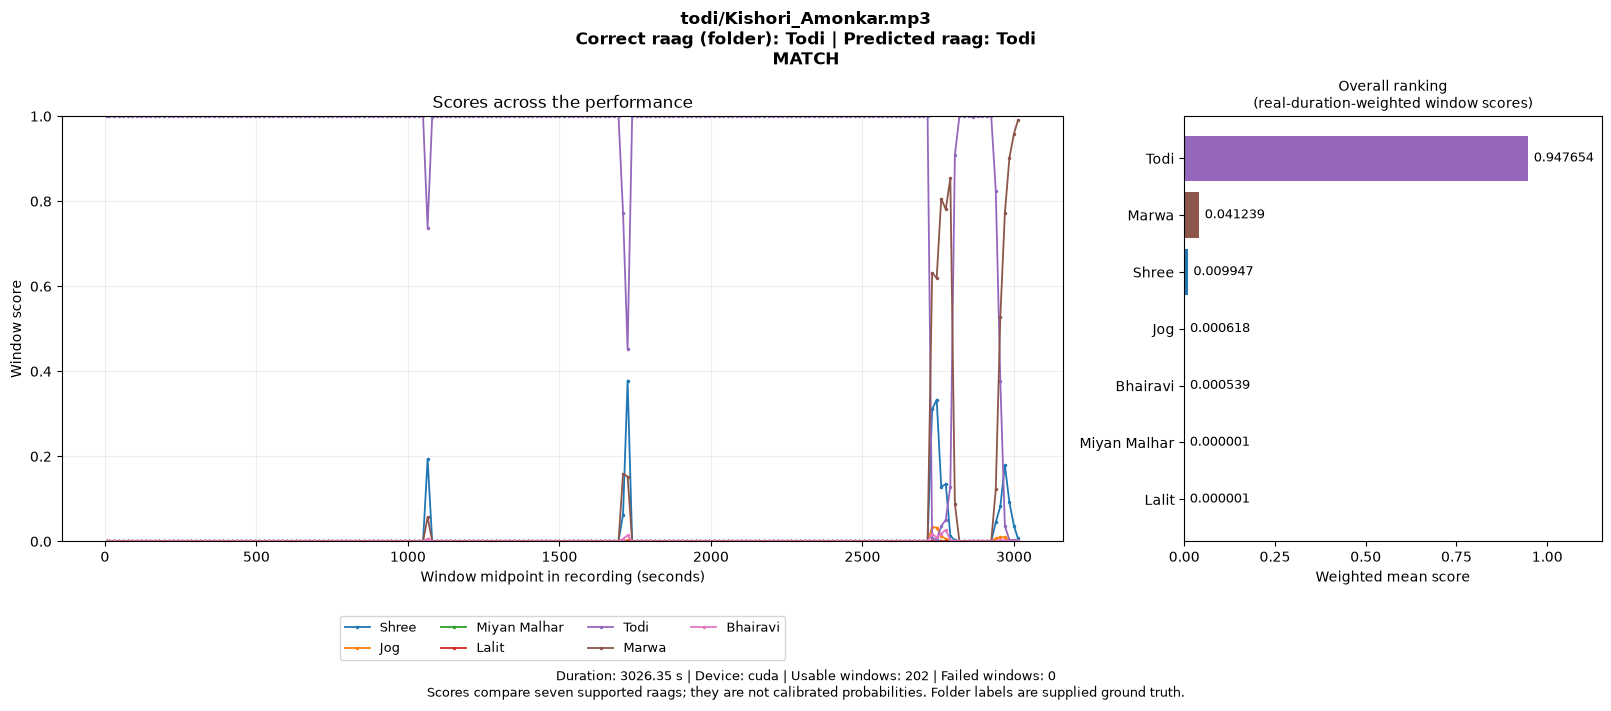

Saved: /home/mushu-cislab/GitHub/MEIKURAL/outputs/ver3/handpicked/todi/Kishori_Amonkar.mp3.png
[19/20] todi/bhimsen_joshi.mp3


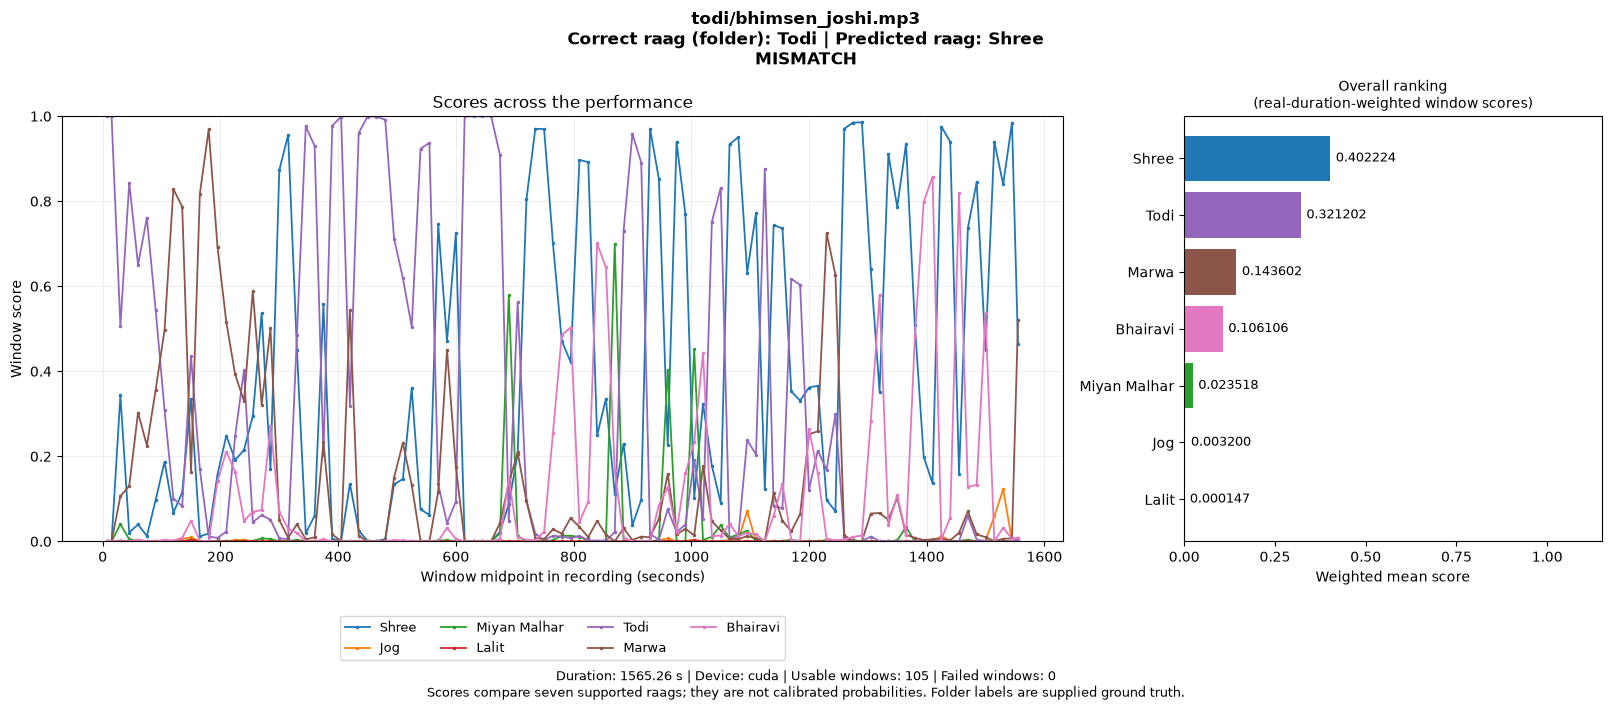

Saved: /home/mushu-cislab/GitHub/MEIKURAL/outputs/ver3/handpicked/todi/bhimsen_joshi.mp3.png
[20/20] todi/rashid_khan.mp3


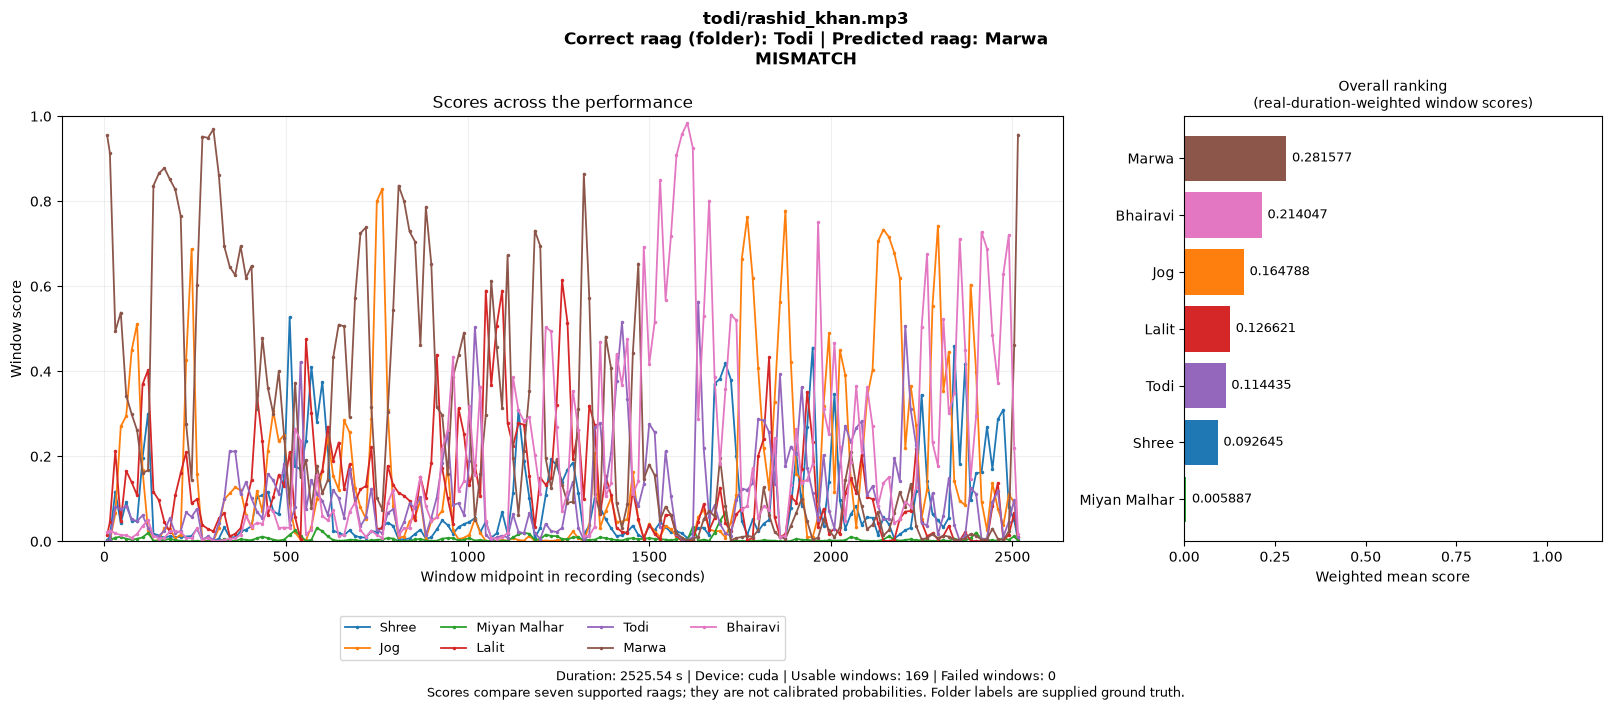

Saved: /home/mushu-cislab/GitHub/MEIKURAL/outputs/ver3/handpicked/todi/rashid_khan.mp3.png
Finished 20 recording reports.


In [4]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
summaries = []
for index, (audio_path, expected) in enumerate(recordings, start=1):
    relative = audio_path.relative_to(TEST_DIR)
    print(f"[{index}/{len(recordings)}] {relative}", flush=True)
    error = None
    try:
        result = predict(audio_path, CHECKPOINT_PATH, device=DEVICE)
    except (OSError, ValueError, RuntimeError, EOFError, pickle.UnpicklingError) as exc:
        result = None
        error = f"{type(exc).__name__}: {exc}"

    fig = performance_figure(result, relative.as_posix(), expected, error=error)
    image_path = OUTPUT_DIR / relative.parent / (relative.name + ".png")
    image_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(image_path, dpi=150, facecolor="white")
    display(fig)
    plt.close(fig)

    ranking = result["ranking"] if result is not None else []
    summaries.append({"audio": relative.as_posix(), "correct_raag": expected,
                      "predicted_raag": ranking[0]["raag"] if ranking else None,
                      "ranking": ranking, "image": str(image_path),
                      "chunk_predictions": [row["top_raag"] if row["scores"] is not None else None
                                            for row in result["windows"]] if result is not None else [],
                      "error": error or (result["message"] if not ranking else None)})
    print(f"Saved: {image_path}", flush=True)
print(f"Finished {len(summaries)} recording reports.")


## Interpreting the figures

The overall ranking is computed by the shared inference pipeline as

\[
\bar p_c = \frac{\sum_j d_j p_{j,c}}{\sum_j d_j},
\]

where \(d_j\) is the **real, unpadded audio duration** of successful window \(j\). This is the same mean as `08_ver3_inference.ipynb`, rather than an unweighted mean. Failed windows are excluded from the ranking and appear as gaps in the timeline. A performance with no usable windows shows no prediction.

Scores compare the seven supported raags; they are **not calibrated probabilities**. The expected label is supplied by the folder, not independently verified from the audio. A folder outside the supported classes is not silently relabelled. “Predicted raag” refers to one of the seven model classes, not a separate thaat/family classifier.

Overlap makes adjacent windows correlated. Absolute pitch, accompaniment, and unfamiliar artists can affect performance. No tonic estimator is used. Recordings used to guide model changes become development examples; keep independent recordings for a final test. See the PNGs in `outputs/ver3/handpicked/` for reports that can be shared without the notebook.

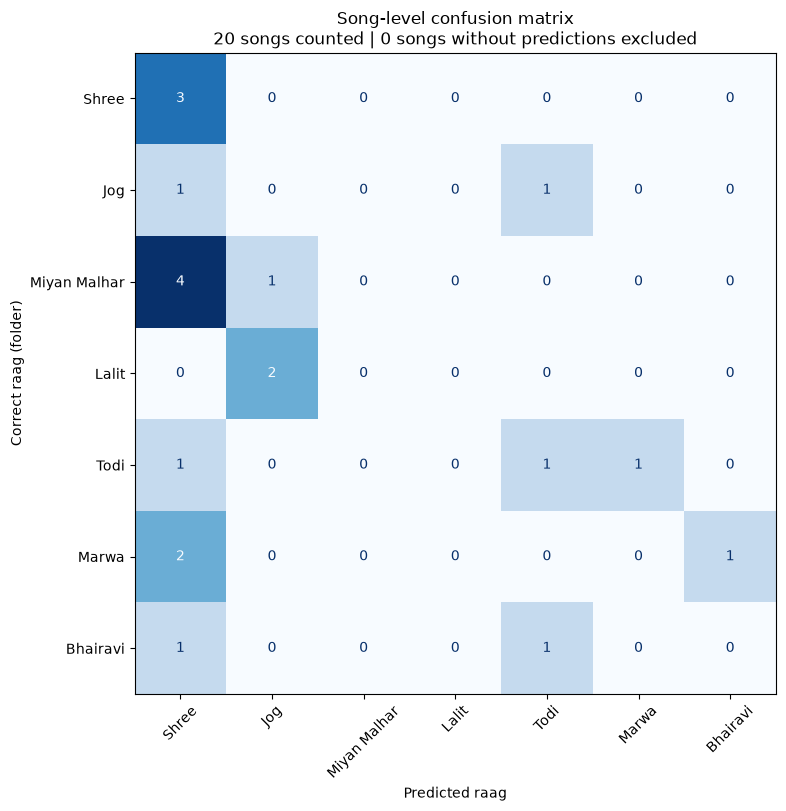

In [5]:
# Song-level confusion matrix: each recording's final weighted-mean prediction is one vote.
from src.ver3.inference.report import confusion_figure

if "summaries" not in globals():
    raise RuntimeError("Run the batch inference cell first.")
song_samples = [row for row in summaries if row["predicted_raag"] is not None]
song_truth = [row["correct_raag"] for row in song_samples]
song_predictions = [row["predicted_raag"] for row in song_samples]
fig = confusion_figure(
    song_truth, song_predictions, classes,
    f"Song-level confusion matrix\n{len(song_samples)} songs counted | "
    f"{len(summaries) - len(song_samples)} songs without predictions excluded")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(OUTPUT_DIR / "confusion_matrix_songs.png", dpi=150, facecolor="white")
display(fig)
plt.close(fig)


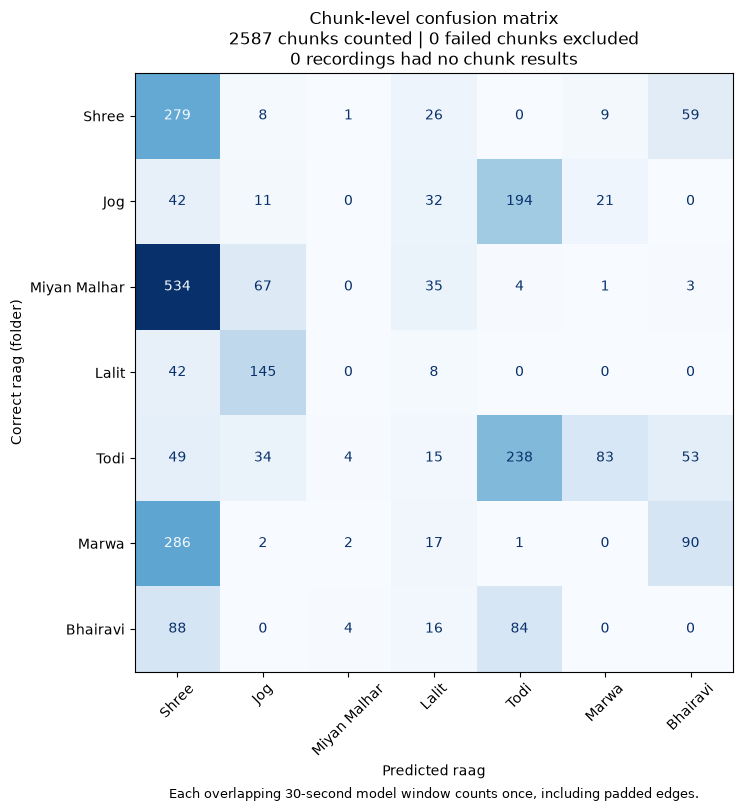

In [6]:
# Chunk-level confusion matrix: each successful model window is one unweighted vote.
# Includes zero-padded edge windows; overlapping windows are correlated.
from src.ver3.inference.report import confusion_figure

if "summaries" not in globals() or any("chunk_predictions" not in row for row in summaries):
    raise RuntimeError("Rerun the updated batch inference cell to retain every chunk's prediction.")
chunk_truth, chunk_predictions = [], []
failed_chunks = 0
for song in summaries:
    for prediction in song["chunk_predictions"]:
        if prediction is None:
            failed_chunks += 1
        else:
            chunk_truth.append(song["correct_raag"])
            chunk_predictions.append(prediction)
missing_chunk_recordings = sum(not row["chunk_predictions"] for row in summaries)
fig = confusion_figure(
    chunk_truth, chunk_predictions, classes,
    f"Chunk-level confusion matrix\n{len(chunk_predictions)} chunks counted | "
    f"{failed_chunks} failed chunks excluded\n"
    f"{missing_chunk_recordings} recordings had no chunk results")
fig.supxlabel("Each overlapping 30-second model window counts once, including padded edges.", fontsize=9)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(OUTPUT_DIR / "confusion_matrix_chunks.png", dpi=150, facecolor="white")
display(fig)
plt.close(fig)
